# Task 1: Bài Toán N-Queen — Logic Mệnh Đề (Glucose3) & Tìm Kiếm Cục Bộ (Min-Conflicts)
Notebook này thực hiện trọn vẹn các thực nghiệm định lượng và vẽ biểu đồ cho Task 1:
1. **Mô hình hóa Logic mệnh đề dạng chuẩn hội (CNF) & Giải bằng Glucose3 (PySAT)** với  \ge 4$ tăng dần.
2. **Tìm kiếm cục bộ Min-Conflicts**: Đối sánh công bằng trên cùng tập trạng thái khởi tạo giữa thuật toán chuẩn (chọn biến xung đột ngẫu nhiên) và **Heuristic đề xuất (Max-Conflict + Danh sách cấm Tabu ngắn hạn & Điều kiện ân xá)**.

In [1]:
import random
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

SOURCE_DIR = Path.cwd().parent
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from task1 import (
    NQueenBoard,
    NQueenCNFEncoder,
    Glucose3NQueenSolver,
    MinConflictsSolver,
    RandomConflictedSelector,
    TabuMaxConflictSelector,
)
FIG_DIR = SOURCE_DIR.parent / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 130
print("Environment ready.")


Environment ready.


## 1. Thực Nghiệm Sinh Mệnh Đề CNF & Thời Gian Giải Của Bộ Giải Glucose3 (PySAT)

In [2]:
sat_sizes = [4, 8, 12, 16, 20, 25, 30, 35, 40, 50, 60]
sat_solver = Glucose3NQueenSolver(include_col_alo=True)
sat_rows = []
sample_12_board = None

for n in sat_sizes:
    enc = NQueenCNFEncoder(n, include_col_alo=True)
    res = sat_solver.solve(n)
    assert res.satisfiable and res.board is not None and res.board.is_valid_solution()
    assert res.num_clauses == enc.theoretical_clause_count()
    if n == 12:
        sample_12_board = res.board
    sat_rows.append({
        'N': n,
        'Variables (N^2)': res.num_variables,
        'Total CNF Clauses': res.num_clauses,
        'Encoding Time (ms)': round(res.encoding_time_sec * 1000, 2),
        'Glucose3 Solve Time (ms)': round(res.solve_time_sec * 1000, 2),
        'Total Time (ms)': round(res.total_time_sec * 1000, 2),
        'Verified': res.board.is_valid_solution(),
    })

df_sat = pd.DataFrame(sat_rows)
df_sat

,N,Variables (N^2),Total CNF Clauses,Encoding Time (ms),Glucose3 Solve Time (ms),Total Time (ms),Verified
0,4,16,84,0.17,0.48,0.65,True
1,8,64,744,0.89,0.67,1.56,True
2,12,144,2620,1.17,1.89,3.06,True
3,16,256,6352,2.96,31.06,34.02,True
4,20,400,12580,17.84,24.65,42.49,True
5,25,625,24850,13.37,28.63,42.00,True
6,30,900,43270,109.44,35.58,145.02,True
7,35,1225,69090,59.19,140.45,199.65,True
8,40,1600,103560,216.92,233.95,450.87,True
9,50,2500,203450,574.92,344.34,919.26,True


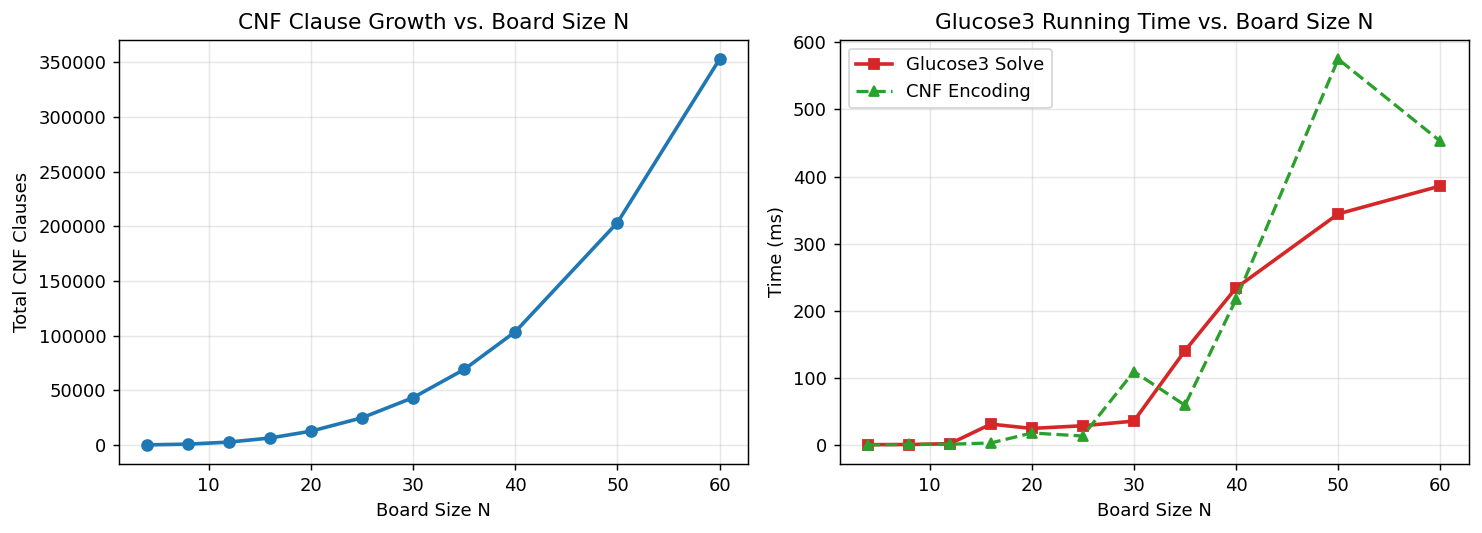

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

axes[0].plot(df_sat['N'], df_sat['Total CNF Clauses'], marker='o', linewidth=2, color='#1f77b4')
axes[0].set_title('CNF Clause Growth vs. Board Size N')
axes[0].set_xlabel('Board Size N')
axes[0].set_ylabel('Total CNF Clauses')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_sat['N'], df_sat['Glucose3 Solve Time (ms)'], marker='s', linewidth=2, color='#d62728', label='Glucose3 Solve')
axes[1].plot(df_sat['N'], df_sat['Encoding Time (ms)'], marker='^', linestyle='--', linewidth=1.8, color='#2ca02c', label='CNF Encoding')
axes[1].set_title('Glucose3 Running Time vs. Board Size N')
axes[1].set_xlabel('Board Size N')
axes[1].set_ylabel('Time (ms)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task1_glucose3_scaling.png', dpi=200)
plt.show()

## 2. Thực Nghiệm Đối Sánh Min-Conflicts Chuẩn Và Heuristic Đề Xuất (Max-Conflict + Tabu)

In [4]:
mc_sizes = [8, 16, 32, 64, 100, 150]
trials = 30
max_steps = 2500

std_solver = MinConflictsSolver(RandomConflictedSelector(), max_steps=max_steps)
tabu_solver = MinConflictsSolver(TabuMaxConflictSelector(), max_steps=max_steps)

mc_rows = []
for n in mc_sizes:
    shared_boards = [NQueenBoard.from_random(n, random.Random(2026 + n * 131 + t)) for t in range(trials)]
    for label, solver in [('Standard Min-Conflicts', std_solver), ('Max-Conflict + Tabu (Proposed)', tabu_solver)]:
        solved_cnt = 0
        steps_list = []
        time_ms_list = []
        for t, b0 in enumerate(shared_boards):
            r = solver.solve(n=n, initial_board=b0, seed=9000 + t)
            if r.solved and r.board.is_valid_solution():
                solved_cnt += 1
            steps_list.append(r.steps)
            time_ms_list.append(r.elapsed_sec * 1000.0)
        mc_rows.append({
            'N': n,
            'Method': label,
            'Success Rate (%)': round(100.0 * solved_cnt / trials, 1),
            'Avg Steps': round(sum(steps_list) / trials, 1),
            'Avg Time (ms)': round(sum(time_ms_list) / trials, 2),
        })

df_mc = pd.DataFrame(mc_rows)
df_mc

,N,Method,Success Rate (%),Avg Steps,Avg Time (ms)
0,8,Standard Min-Conflicts,96.7,129.5,1.47
1,8,Max-Conflict + Tabu (Proposed),90.0,264.9,5.79
2,16,Standard Min-Conflicts,100.0,85.7,1.61
3,16,Max-Conflict + Tabu (Proposed),100.0,29.6,1.82
4,32,Standard Min-Conflicts,100.0,80.9,3.63
5,32,Max-Conflict + Tabu (Proposed),100.0,45.1,3.08
6,64,Standard Min-Conflicts,100.0,107.2,10.21
7,64,Max-Conflict + Tabu (Proposed),100.0,63.5,6.73
8,100,Standard Min-Conflicts,100.0,138.7,20.04
9,100,Max-Conflict + Tabu (Proposed),100.0,87.4,30.51


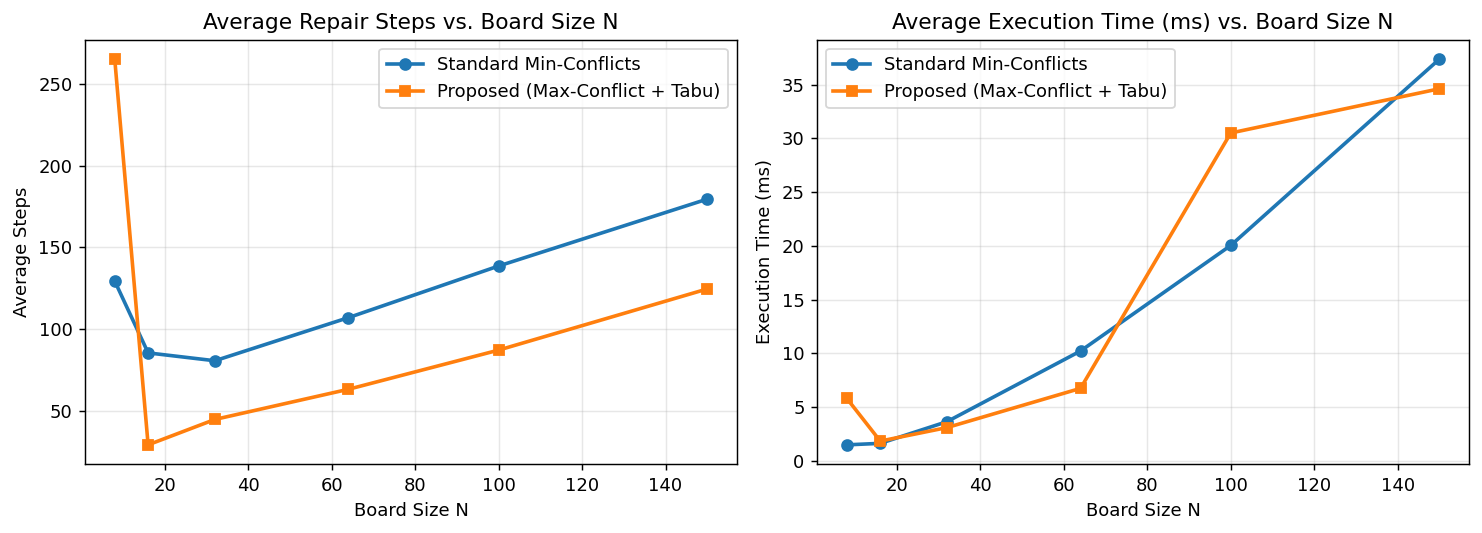

In [5]:
df_std = df_mc[df_mc['Method'] == 'Standard Min-Conflicts']
df_tabu = df_mc[df_mc['Method'] == 'Max-Conflict + Tabu (Proposed)']

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(df_std['N'], df_std['Avg Steps'], marker='o', linewidth=2, label='Standard Min-Conflicts')
axes[0].plot(df_tabu['N'], df_tabu['Avg Steps'], marker='s', linewidth=2, label='Proposed (Max-Conflict + Tabu)')
axes[0].set_title('Average Repair Steps vs. Board Size N')
axes[0].set_xlabel('Board Size N')
axes[0].set_ylabel('Average Steps')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_std['N'], df_std['Avg Time (ms)'], marker='o', linewidth=2, label='Standard Min-Conflicts')
axes[1].plot(df_tabu['N'], df_tabu['Avg Time (ms)'], marker='s', linewidth=2, label='Proposed (Max-Conflict + Tabu)')
axes[1].set_title('Average Execution Time (ms) vs. Board Size N')
axes[1].set_xlabel('Board Size N')
axes[1].set_ylabel('Execution Time (ms)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task1_min_conflicts_comparison.png', dpi=200)
plt.show()